# What is Function transformer?

* The aim of `Function transformer` is to transform the dataset's distribution to normal distribution.
* This is bcz in statistics, while solving any problem, if we get normal distribution, it becomes very easy to get the solution.

In [3]:
import pandas as pd
import numpy as np


In [4]:
df = pd.read_csv("00 Titanic.csv",  usecols = ['Age', 'Fare', 'Survived'])

In [5]:
df.sample(5)

,Survived,Age,Fare
162,0,26.0,7.775
188,0,40.0,15.500
113,0,20.0,9.825
51,0,21.0,7.800
183,1,1.0,39.000


In [6]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [7]:
df["Age"] = df["Age"].fillna(df['Age'].mean())

In [8]:
df['Age'].isnull().sum()

0

# 1) Train/test split

In [7]:
x = df[['Age', 'Fare']]
y = df.drop(x, axis = 'columns')

print(x.head(2))
print()
print()
print()
print(y.head(2))


    Age     Fare
0  22.0   7.2500
1  38.0  71.2833



   Survived
0         0
1         1


In [8]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.7)

# Checking the initial distribution of the data.

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

C:\Users\jugal\AppData\Local\Temp\ipykernel_1640\1268852286.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Age'])


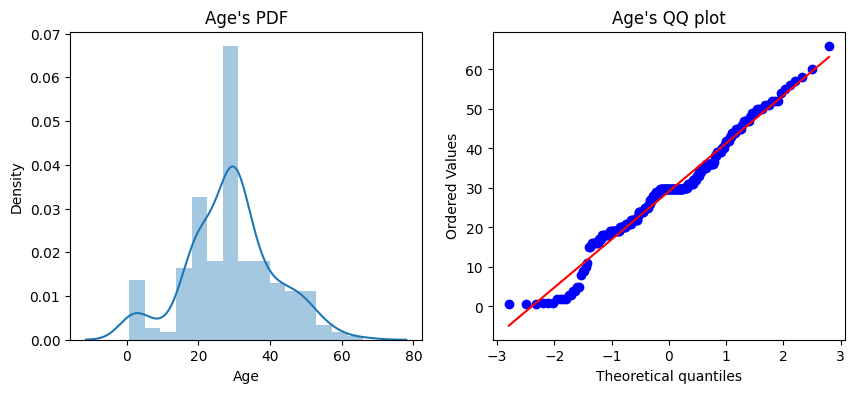

In [10]:
plt.figure(figsize = (10, 4))
plt.subplot(121)
sns.distplot(x_train['Age'])
plt.title("Age's PDF")

plt.subplot(122)
stats.probplot(x_train['Age'], dist = 'norm', plot = plt)
plt.title("Age's QQ plot")

plt.show()

C:\Users\jugal\AppData\Local\Temp\ipykernel_1640\2142453581.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Fare'])


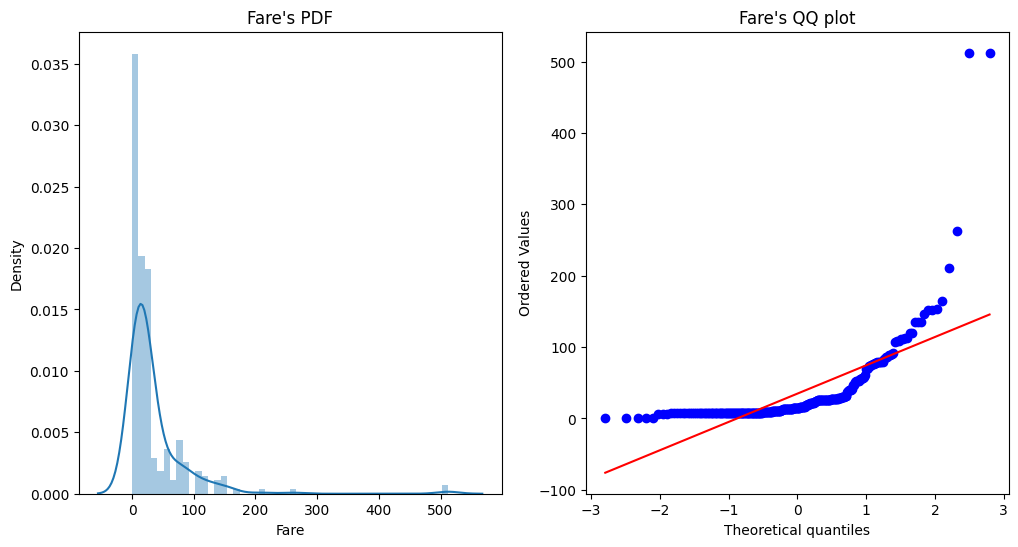

In [11]:
# Fare column

plt.figure(figsize = (12, 6))
plt.subplot(121)
sns.distplot(x_train['Fare'])
plt.title("Fare's PDF")

plt.subplot(122)
stats.probplot(x_train['Fare'], dist = 'norm', plot = plt)
plt.title("Fare's QQ plot")
plt.show()

# Model building, predicting and finding accuracy before applying `FunctionTransformer`.

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

In [13]:
lr = LogisticRegression()
dt = DecisionTreeClassifier(criterion = 'entropy')

In [14]:
lr.fit(x_train, y_train)
dt.fit(x_train, y_train)

C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


DecisionTreeClassifier(criterion='entropy')

In [15]:
pred_lr = lr.predict(x_test)
pred_dt = dt.predict(x_test)

In [16]:
from sklearn.metrics import accuracy_score

acc_lr = accuracy_score(pred_lr, y_test)
acc_dt = accuracy_score(pred_dt, y_test)

print(f'Accuracy of Logistic regression: {acc_lr}')
print(f"Accuracy of Decision tree: {acc_dt}")

Accuracy of Logistic regression: 0.6506410256410257
Accuracy of Decision tree: 0.6153846153846154


# After FunctionTransformer

In [17]:
from sklearn.preprocessing import FunctionTransformer

ft = FunctionTransformer(func = np.log1p)

# Here we're applying log transformer.
# np.log gives error if any value is 0 bcz log0 is not possible, wheres
# np.log1p will add 1 to the value first and then transform


In [18]:
x_train_transformed = ft.fit_transform(x_train)
x_test_transformed = ft.transform(x_test)

In [19]:
# Fitting into the model

lr.fit(x_train_transformed, y_train)
dt.fit(x_train_transformed, y_train)

C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


DecisionTreeClassifier(criterion='entropy')

In [20]:
# Predicting

pred_lr_2 = lr.predict(x_test_transformed)
pred_dt_2 = dt.predict(x_test_transformed)

In [21]:
# Getting accuracy_score

acc_lr_2 = accuracy_score(pred_lr_2, y_test)
acc_dt_2 = accuracy_score(pred_dt_2, y_test)

print(f'Accuracy of Logistic regression after FunctionTransformer: {acc_lr_2}')
print(f"Accuracy of Decision tree after FunctionTransformer: {acc_dt_2}")

Accuracy of Logistic regression after FunctionTransformer: 0.6650641025641025
Accuracy of Decision tree after FunctionTransformer: 0.6089743589743589


C:\Users\jugal\AppData\Local\Temp\ipykernel_1640\2433426460.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Age'])
C:\Users\jugal\AppData\Local\Temp\ipykernel_1640\2433426460.py:10: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train_transformed['Age'])


Text(0.5, 1.0, "Age's PDF after Function Transformation.")

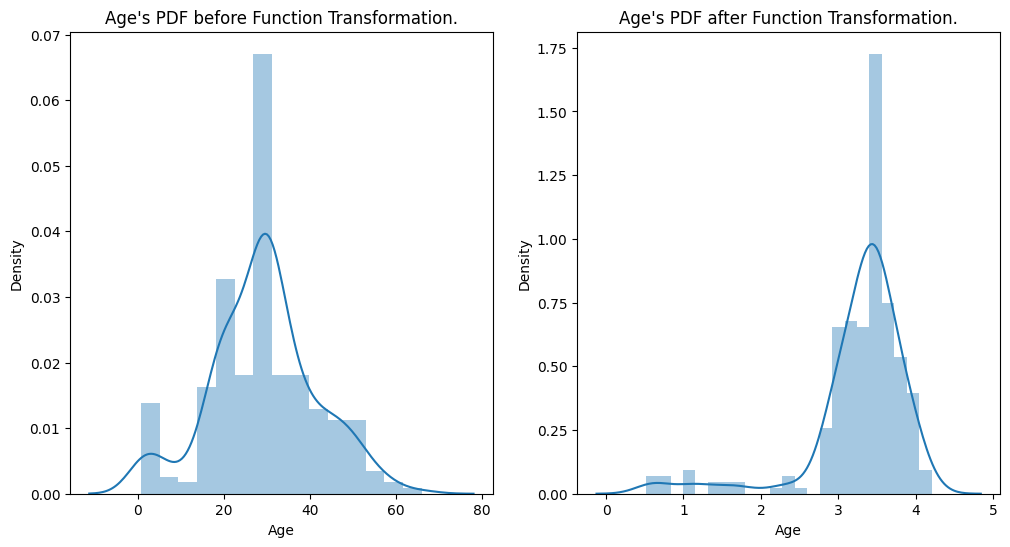

In [22]:
# Graphical representation

plt.figure(figsize = (12, 6))

plt.subplot(121)
sns.distplot(x_train['Age'])
plt.title("Age's PDF before Function Transformation.")

plt.subplot(122)
sns.distplot(x_train_transformed['Age'])
plt.title("Age's PDF after Function Transformation.")

C:\Users\jugal\AppData\Local\Temp\ipykernel_1640\1424830807.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Fare'])
C:\Users\jugal\AppData\Local\Temp\ipykernel_1640\1424830807.py:10: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train_transformed['Fare'])


Text(0.5, 1.0, "Fare's PDF after Function Transformation.")

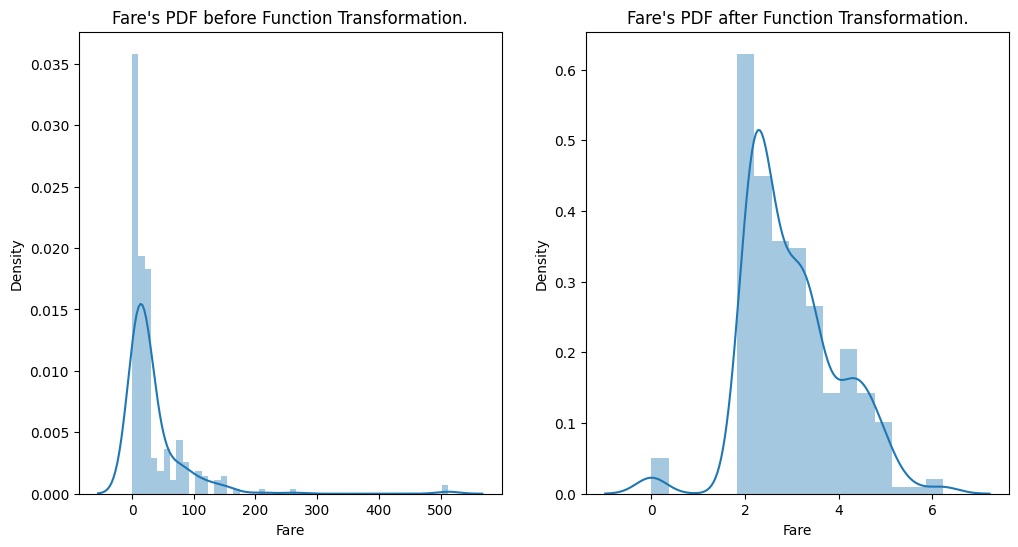

In [23]:
# Graphical representation of Fare column.

plt.figure(figsize = (12, 6))

plt.subplot(121)
sns.distplot(x_train['Fare'])
plt.title("Fare's PDF before Function Transformation.")

plt.subplot(122)
sns.distplot(x_train_transformed['Fare'])
plt.title("Fare's PDF after Function Transformation.")

In [24]:
# We can see that it changed from Skewed distribution to Normal distribution after applying Function Transformation.

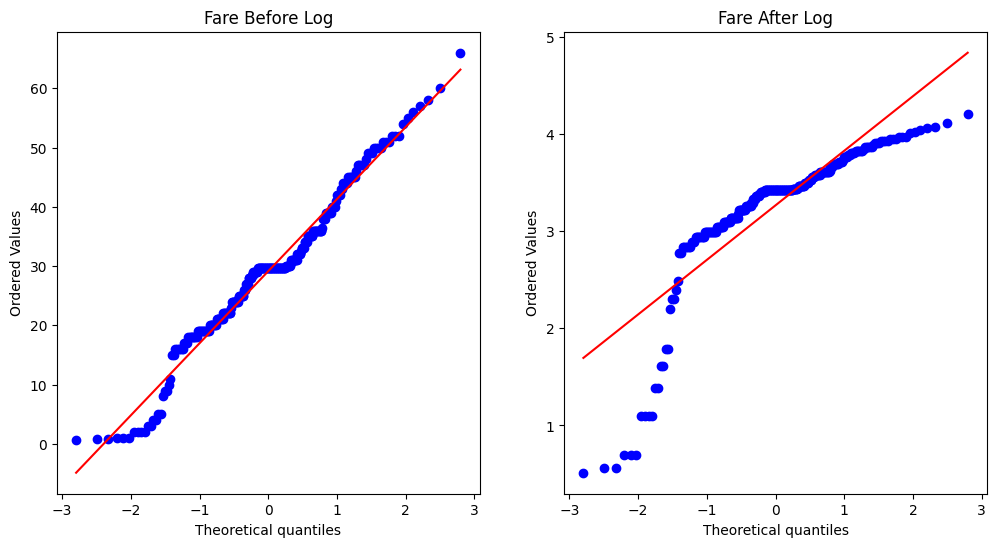

In [25]:
plt.figure(figsize=(12,6))

plt.subplot(121)
stats.probplot(x_train['Age'], dist="norm", plot=plt)
plt.title('Fare Before Log')

plt.subplot(122)
stats.probplot(x_train_transformed['Age'], dist="norm", plot=plt)
plt.title('Fare After Log')

plt.show()

In [26]:
# We can see the result on 'Age' from QQ Plot. 

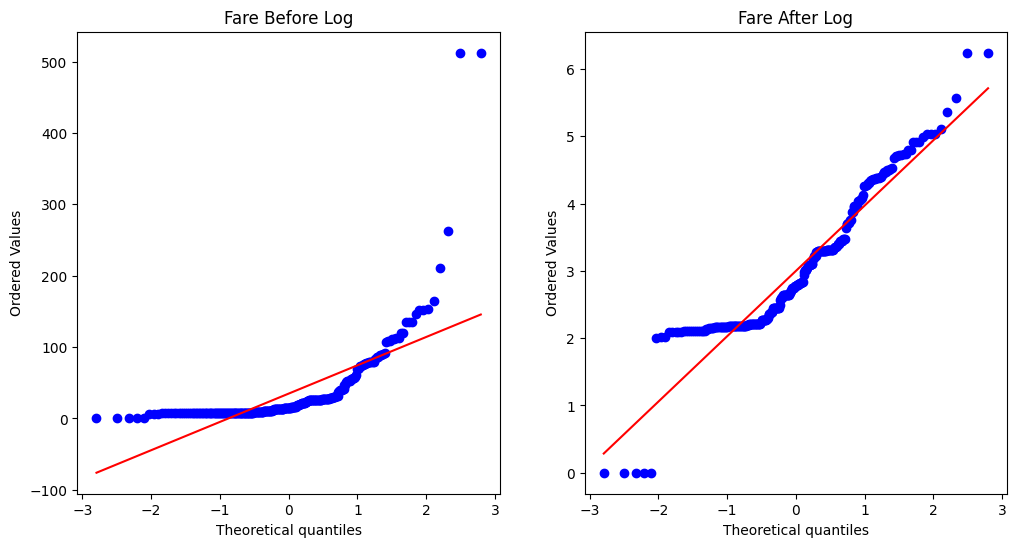

In [27]:
plt.figure(figsize=(12,6))

plt.subplot(121)
stats.probplot(x_train['Fare'], dist = "norm", plot = plt)
plt.title('Fare Before Log')

plt.subplot(122)
stats.probplot(x_train_transformed['Fare'], dist = "norm", plot = plt)
plt.title('Fare After Log')

plt.show()

# We can see we are not getting the desired result after applying Function Transformation on 'Age column'. So let's only apply it to 'Fare' column.

In [28]:
from sklearn.compose import ColumnTransformer

In [29]:
data_fare = [
    ('Log', FunctionTransformer(func = np.log1p), ['Fare'])
]

ct = ColumnTransformer(transformers = data_fare, remainder = 'passthrough')

In [30]:
x_train_trans2 = ct.fit_transform(x_train)
x_test_trans2 = ct.transform(x_test)

In [31]:
lr.fit(x_train_trans2, y_train)
dt.fit(x_train_trans2, y_train)

C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


DecisionTreeClassifier(criterion='entropy')

In [32]:
pred_lr3 = lr.predict(x_test_trans2)
pred_dt3 = dt.predict(x_test_trans2)

In [33]:
acc_lr3 = accuracy_score(pred_lr3, y_test)
acc_dt3 = accuracy_score(pred_lr3, y_test)

In [34]:
print(f"Accuracy of Logistic Regression: {acc_lr3}.")
print(f"Accuracy of Decision Tree: {acc_dt3}.")

Accuracy of Logistic Regression: 0.6634615384615384.
Accuracy of Decision Tree: 0.6634615384615384.


# Let's create a function for Function Transformer.

In [1]:
def apply_func_trans(transformer):
    x = df.iloc[:,1:3]
    y = df.Survived

    trans_data = [
        ("LogTransformer", FunctionTransformer(func = np.log1p), ['Fare'])
    ]

    ct = ColumnTransformer(transformers = trans_data, remainder = 'passthrough')
    x_trans = ct.fit_transform(x)

    lr = LogisticRegression()
    
    from sklearn.model_selection import cross_val_score

    acc_max = cross_val_score(lr, X = x_trans, y = y, scoring = 'accuracy', cv = 10).mean()
    print(f'Average accuracy: {acc_max}.')

    # Graphical represenation of 'Fare'.
    plt.figure(figsize = (12, 6))

    plt.subplot(121)
    sns.distplot(x['Fare'])
    plt.title("Distribution of Fare before FunctionTransformation.")

    plt.subplot(122)
    sns.distplot(x_trans[:,0])
    plt.title("Distribution of Fare after FunctionTransformation.")

    plt.show()

In [9]:
apply_func_trans(lambda x:1/x)

NameError: name 'FunctionTransformer' is not defined

# `Next`: 03 Practise of FunctionTransformer on `Brainstroke` dataset.